# Rôle 2 : analyse non supervisée des 2 000 projets

Ce notebook suit les tâches du rôle 2 (`docs/plan-role2.md`) :

1. **préparation des données** (ce qui suit) ;
2. ACP ;
3. clustering (K-means, hiérarchique, DBSCAN, mélange gaussien).

Le fichier `anomalies_injectees.csv` (vérité terrain) n'est **pas** lu ici : l'analyse non supervisée n'utilise aucune étiquette.

## Tâche 1 : préparation des données

### Choix des variables

`projets.csv` n'a que trois colonnes chiffrées réelles : le coût, la durée et l'année d'approbation. Pour que les groupes parlent la langue du classement, on ajoute les cinq critères que l'agent calcule pour chaque projet :

- `rentabilite_predite` et `proba_risque`, donnés par `predict` (rôle 1) ;
- `impact_env_social`, `alignement_strategique` et `faisabilite`, notes de 1 à 5 données par `extract` (rôle 3) à partir du document du projet.

Soit **8 variables**. Le secteur, la région et le type de financement ne servent qu'à **décrire** les groupes ensuite, pas à les former.

À garder en tête :

- **Exclues** : les cibles `rentabilite` et `risque`. Elles sont vides pour les 500 projets en cours et simulées par une formule.
- **Redondance** : la rentabilité et le risque prédits sont calculés par le rôle 1 à partir du coût, de la durée, de l'année, du secteur et du pays. Ils sont donc en partie redondants avec les trois chiffres, et l'ACP le montrera.
- **Projets déjà vus** : pour les 1 500 projets terminés, ces prédictions portent sur des projets vus pendant l'apprentissage du rôle 1. Elles collent donc mieux aux vraies valeurs que pour un projet nouveau. Cela ne gêne pas une analyse descriptive comme celle-ci, qui ne mesure aucune performance de prédiction.
- **Anomalies gardées** : les 40 anomalies fabriquées restent dans les données. Une analyse non supervisée ne sait pas lesquelles sont fausses : elles apparaîtront comme des points isolés.

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

RACINE = Path.cwd().resolve().parents[1]  # le notebook s'exécute depuis notebooks/role2
sys.path.insert(0, str(RACINE))
logging.basicConfig(level=logging.WARNING)

from src.nlp import extract
from src.supervise import predict

FIGURES = RACINE / "reports" / "role2" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140)
GRAINE = 42

In [2]:
projets = pd.read_csv(RACINE / "data" / "processed" / "projets.csv")
colonnes_fiche = ["id_projet", "nom", "secteur", "pays", "region", "cout_total", "duree_mois",
                  "annee_approbation", "type_financement"]
NOTES = ["impact_env_social", "alignement_strategique", "faisabilite"]

lignes = []
for fiche in projets[colonnes_fiche].to_dict("records"):  # fiche sans les cibles, comme pour l'agent
    prediction = predict(fiche)
    notes = extract((RACINE / "data" / "docs" / f"{fiche['id_projet']}.txt").read_text(encoding="utf-8"))
    lignes.append({"id_projet": fiche["id_projet"],
                   "rentabilite_predite": prediction["rentabilite_predite"],
                   "proba_risque": prediction["proba_risque"],
                   **{c: notes[c] for c in NOTES}})
donnees = projets.merge(pd.DataFrame(lignes), on="id_projet")
print(donnees.shape)
donnees.head(3)

(2000, 17)


,id_projet,nom,secteur,pays,region,cout_total,duree_mois,annee_approbation,type_financement,statut,rentabilite,risque,rentabilite_predite,proba_risque,impact_env_social,alignement_strategique,faisabilite
0,P000001,West Africa Pilot Community-based Natural Reso...,Gouvernance,Africa,Afrique,13.19,106,1995,Autre,termine,5.5,eleve,4.81,0.355200,4,3,3
1,P000034,INFRASTRUCTURE REHAB,Transport,Angola,Afrique de l'Est et australe,23.20,92,1991,IDA,termine,6.9,faible,7.48,0.067053,2,1,2
2,P000044,Financial Institutions modernization project,Finance,Angola,Afrique de l'Est et australe,21.00,116,1992,IDA,termine,4.1,moyen,5.50,0.464793,3,3,4


### Valeurs manquantes

Seules les cibles sont vides (les 500 projets en cours). Elles ne servent pas ici. Les 8 variables retenues sont complètes : il n'y a rien à remplacer.

In [3]:
VARIABLES_BRUTES = ["cout_total", "duree_mois", "annee_approbation", "rentabilite_predite",
                    "proba_risque", *NOTES]
print(donnees.isna().sum()[lambda s: s > 0].to_string())
print("Manquants dans les 8 variables :", int(donnees[VARIABLES_BRUTES].isna().sum().sum()))

rentabilite    500
risque         500
Manquants dans les 8 variables : 0


### Asymétrie et log du coût

Le coût va de 1 à près de 38 000 millions de dollars. Quelques projets géants écraseraient tous les autres dans une méthode fondée sur des distances. Le log10 rend la distribution à peu près symétrique : un projet de 10 M$ et un de 100 M$ sont alors aussi éloignés qu'un de 100 M$ et un de 1 000 M$.

In [4]:
asymetrie = donnees[VARIABLES_BRUTES].skew().rename("asymétrie").to_frame()
donnees["log_cout"] = np.log10(donnees["cout_total"])
asymetrie.loc["log_cout (log10 du coût)"] = donnees["log_cout"].skew()
asymetrie.round(2)

,asymétrie
cout_total,18.52
duree_mois,0.10
annee_approbation,-0.42
rentabilite_predite,0.14
proba_risque,1.12
impact_env_social,-0.79
alignement_strategique,-0.98
faisabilite,-0.65
log_cout (log10 du coût),0.06


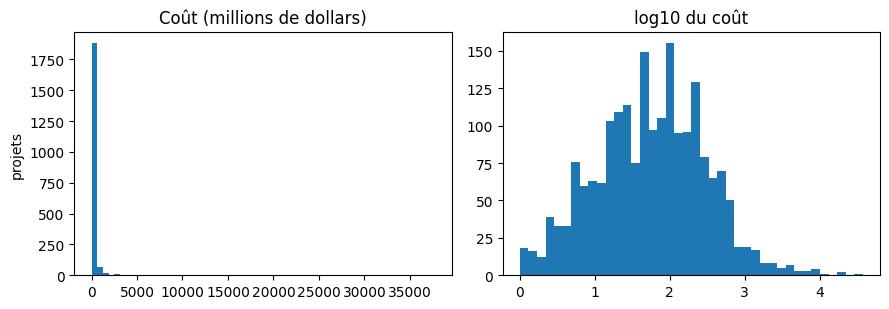

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].hist(donnees["cout_total"], bins=60, color="tab:blue")
axes[0].set_title("Coût (millions de dollars)")
axes[0].set_ylabel("projets")
axes[1].hist(donnees["log_cout"], bins=40, color="tab:blue")
axes[1].set_title("log10 du coût")
fig.tight_layout()
fig.savefig(FIGURES / "cout_avant_apres_log.png", dpi=150)
plt.show()

Les autres variables gardent leur échelle : la durée et l'année sont à peu près symétriques. La probabilité de risque et les notes sont asymétriques, mais bornées : il n'y a pas de valeur géante à écraser.

### Liens entre variables

On s'attend à ce que la rentabilité et le risque prédits soient liés au coût et à la durée, puisque le rôle 1 les calcule à partir d'eux.

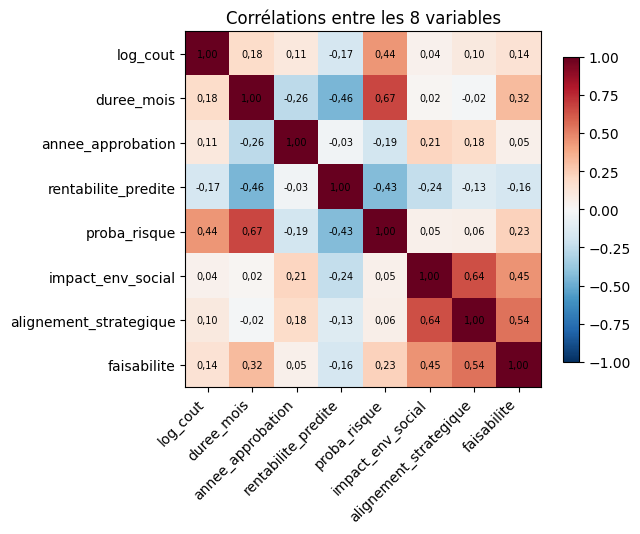

In [6]:
VARIABLES = ["log_cout", "duree_mois", "annee_approbation", "rentabilite_predite", "proba_risque", *NOTES]
correlations = donnees[VARIABLES].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(VARIABLES)), VARIABLES, rotation=45, ha="right")
ax.set_yticks(range(len(VARIABLES)), VARIABLES)
for i in range(len(VARIABLES)):
    for j in range(len(VARIABLES)):
        ax.text(j, i, f"{correlations.iat[i, j]:.2f}".replace(".", ","), ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, shrink=0.8)
ax.set_title("Corrélations entre les 8 variables")
fig.tight_layout()
fig.savefig(FIGURES / "correlations_variables.png", dpi=150)
plt.show()

### Standardisation

L'ACP, K-means, la classification hiérarchique et DBSCAN mesurent des distances. Sans mise à l'échelle, l'année (de 1987 à 2026) pèserait des centaines de fois plus que la probabilité de risque (de 0 à 1). `StandardScaler` centre chaque variable (moyenne 0) et la réduit (écart-type 1) : chacune compte autant.

In [7]:
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(donnees[VARIABLES]), columns=VARIABLES, index=donnees["id_projet"])
X.describe().loc[["mean", "std", "min", "max"]].round(2)

,log_cout,duree_mois,annee_approbation,rentabilite_predite,proba_risque,impact_env_social,alignement_strategique,faisabilite
mean,-0.00,-0.00,0.00,0.00,-0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.39,-2.10,-2.40,-3.29,-0.94,-2.82,-3.42,-3.12
max,3.87,3.46,1.46,3.47,2.66,1.02,1.20,0.90


In [8]:
# Points extrêmes après standardisation (à plus de 4 écarts-types sur au moins une variable)
extremes = (X.abs() > 4).any(axis=1)
print(f"{int(extremes.sum())} projets à plus de 4 écarts-types sur au moins une variable")
print((X.abs() > 4).sum()[lambda s: s > 0].to_string())

0 projets à plus de 4 écarts-types sur au moins une variable
Series([], )


### Bilan de la préparation

- **Table d'analyse** : 2 000 projets, 8 variables standardisées (`X`) : log10 du coût, durée, année, rentabilité prédite, probabilité de risque, et les trois notes qualitatives. Aucune valeur manquante. Le secteur, la région et le type de financement restent à côté, pour décrire les groupes.
- **Log du coût** : l'asymétrie passe de 18,5 à 0,06.
- **Deux blocs de variables liées** :
  - **chiffres et prédictions** : la probabilité de risque suit la durée (corrélation 0,67) et le coût (0,44) ; la rentabilité prédite baisse avec la durée (−0,46). C'est la redondance attendue, puisque le rôle 1 calcule ces prédictions à partir du coût et de la durée ;
  - **notes du texte** : impact, alignement et faisabilité sont liés entre eux (0,45 à 0,64) mais presque pas aux chiffres (moins de 0,25 en valeur absolue, sauf faisabilité et durée, 0,32).

  On peut s'attendre à ce que l'ACP retrouve ces deux blocs comme ses deux premiers axes (tâche 2).
- **Pas de point extrême après standardisation** : aucun projet n'est à plus de 4 écarts-types sur une variable. Les anomalies fabriquées ne se voient donc pas variable par variable. Un coût multiplié par 10 à 50 ajoute 1 à 1,7 au log10 (dont l'écart-type vaut 0,73), soit 1,4 à 2,3 écarts-types. C'est en combinant les variables (le coût par mois, par exemple) que l'Isolation Forest de `detect_anomalies` les repère en partie.
